<a href="https://colab.research.google.com/github/sefaeroglu2026/ppg-nabiz-kestirimi/blob/main/sefaerogluproje_md_adl%C4%B1_not_defterinin_kopyas%C4%B1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [47]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Gerçek EKG nabızlarının bulunduğu ana referans dosyasını linkten oku
url_ann = "https://physionet.org/files/butppg/2.0.0/quality-hr-ann.csv"
ann = pd.read_csv(url_ann)

# 2. Dosyanın içeriğini ve sütunlarını kontrol et
print("--- REFERANS TABLOSU İLK 5 SATIR ---")
print(ann.head())
print("\nToplam satır sayısı:", len(ann))
print("Sütun adları:", list(ann.columns))

--- REFERANS TABLOSU İLK 5 SATIR ---
       ID  Quality  HR
0  100001        1  83
1  100002        1  85
2  100003        1  81
3  100004        0  85
4  101001        1  67

Toplam satır sayısı: 3888
Sütun adları: ['ID', 'Quality', 'HR']


In [48]:
!pip install wfdb

--- İLK KAYIT SONUÇLARI (100001) ---
Örnekleme Frekansı: 30 Hz
Toplam Örnek Sayısı: 300 (Süre: 10.0 saniye)
Gerçek EKG Nabzı: 83 atım/dk
Ham Tepe Sayısı: 71 adet
Ham Tahmin Nabız: 426.0 atım/dk
İlk Kayıt Hatası: 343.0 atım/dk


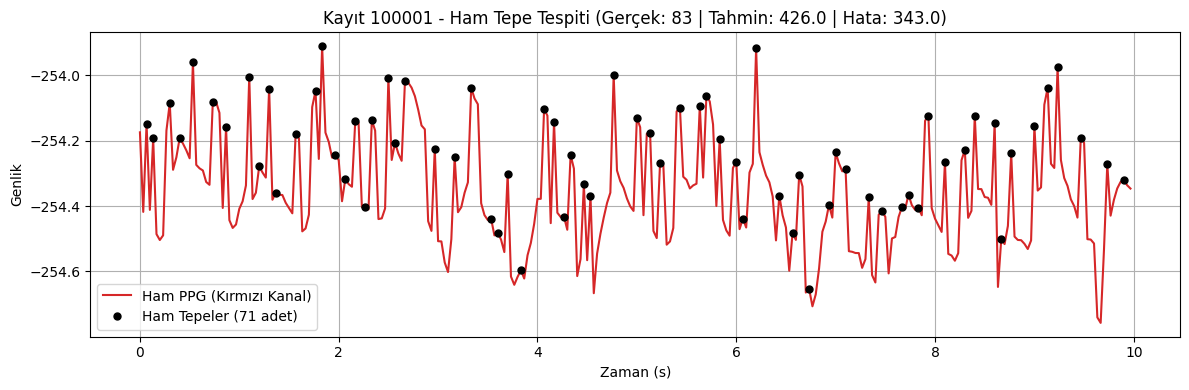

In [49]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# 1. İlk hastanın ID'sini ve referans EKG nabzını al
kayit_id = ann['ID'].iloc[0]
gercek_hr = ann['HR'].iloc[0]

# 2. Sinyali doğrudan PhysioNet üzerinden oku
record = wfdb.rdrecord(f"{kayit_id}_PPG", pn_dir=f"butppg/2.0.0/{kayit_id}")
fs = record.fs  # 30 Hz
raw_sig = record.p_signal

# Matris yapısını analiz et ve hocanın kuralına göre kırmızı kanalı al
if raw_sig.shape[0] == 1:
    # 1x300 yatay vektör durumu
    ppg = raw_sig.flatten()
elif raw_sig.ndim == 2 and raw_sig.shape[1] >= 3:
    # 3 sütunlu (RGB) durum: İlk sütun kırmızı kanaldır
    ppg = raw_sig[:, 0]
elif raw_sig.ndim == 2 and raw_sig.shape[0] >= 3 and raw_sig.shape[1] > raw_sig.shape[0]:
    # 3 satırlı (RGB) durum: İlk satır kırmızı kanaldır
    ppg = raw_sig[0, :]
else:
    ppg = raw_sig.flatten()

# 3. Zaman ekseni ve süre hesabı
ornek_sayisi = len(ppg)
sure = ornek_sayisi / fs
zaman = np.arange(ornek_sayisi) / fs

# 4. Baseline: Ham tepe sayımı (filtresiz doğrudan yerel tepe bulma)
tepeler, _ = find_peaks(ppg)
tepe_sayisi = len(tepeler)

# 10 saniyedeki tepe adedini dakikalık nabza (atım/dk) çevir
tahmin_hr = tepe_sayisi * (60.0 / sure)
hata = abs(tahmin_hr - gercek_hr)

print(f"--- İLK KAYIT SONUÇLARI ({kayit_id}) ---")
print(f"Örnekleme Frekansı: {fs} Hz")
print(f"Toplam Örnek Sayısı: {ornek_sayisi} (Süre: {sure:.1f} saniye)")
print(f"Gerçek EKG Nabzı: {gercek_hr} atım/dk")
print(f"Ham Tepe Sayısı: {tepe_sayisi} adet")
print(f"Ham Tahmin Nabız: {tahmin_hr:.1f} atım/dk")
print(f"İlk Kayıt Hatası: {hata:.1f} atım/dk")

# 5. Sinyali ve tespit edilen ham tepeleri çiz ve kaydet
plt.figure(figsize=(12, 4))
plt.plot(zaman, ppg, label='Ham PPG (Kırmızı Kanal)', color='tab:red')
plt.plot(zaman[tepeler], ppg[tepeler], 'ko', markersize=5, label=f'Ham Tepeler ({tepe_sayisi} adet)')
plt.title(f"Kayıt {kayit_id} - Ham Tepe Tespiti (Gerçek: {gercek_hr} | Tahmin: {tahmin_hr:.1f} | Hata: {hata:.1f})")
plt.xlabel("Zaman (s)")
plt.ylabel("Genlik")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig('sekil1.png', dpi=150)
plt.show()

In [50]:
import urllib.request

# Başlık dosyasının (.hea) içeriğini doğrudan oku ve yazdır
hea_metni = urllib.request.urlopen("https://physionet.org/files/butppg/2.0.0/100001/100001_PPG.hea").read().decode()
print("100001_PPG.hea içeriği:\n")
print(hea_metni)

100001_PPG.hea içeriği:

100001_PPG 300 30 1
100001_PPG.dat 16 -128.9152(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.792(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.9284(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.7951(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.9058(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.7576(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.7485(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.7557(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.9179(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.9603(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.8572(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.8765(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.9064(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.8977(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.8874(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.875(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -129.024(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128.8648(-32767)/a.u. 0 0 0 0 0 
100001_PPG.dat 16 -128

In [51]:
# 1. Referans tablosundaki ilk 10 kaydı al
ilk_10_df = ann.head(10)

hatalar = []
bes_alti_sayisi = 0

print("--- İLK 10 KAYIT İÇİN BASELINE (HAM TEPE) ANALİZİ ---")

for i, row in ilk_10_df.iterrows():
    kid = row['ID']
    gercek_hr = row['HR']

    # Sinyali doğrudan oku
    rec = wfdb.rdrecord(f"{kid}_PPG", pn_dir=f"butppg/2.0.0/{kid}")
    fs = rec.fs
    raw_sig = rec.p_signal

    # Kırmızı kanalı (ilk kanal/satır) ayıkla
    if raw_sig.shape[0] == 1:
        ppg = raw_sig.flatten()
    elif raw_sig.ndim == 2 and raw_sig.shape[1] >= 3:
        ppg = raw_sig[:, 0]
    elif raw_sig.ndim == 2 and raw_sig.shape[0] >= 3 and raw_sig.shape[1] > raw_sig.shape[0]:
        ppg = raw_sig[0, :]
    else:
        ppg = raw_sig.flatten()

    sure = len(ppg) / fs

    # Ham tepe sayımı (Baseline)
    tepeler, _ = find_peaks(ppg)
    tepe_sayisi = len(tepeler)
    tahmin_hr = tepe_sayisi * (60.0 / sure)

    hata = abs(tahmin_hr - gercek_hr)
    hatalar.append(hata)

    if hata < 5.0:
        bes_alti_sayisi += 1

    print(f"Kayıt {kid}: Gerçek = {gercek_hr:2d} | Tahmin = {tahmin_hr:5.1f} | Hata = {hata:5.1f} atım/dk")

baseline_mae = np.mean(hatalar)
yuzde_5 = (bes_alti_sayisi / len(ilk_10_df)) * 100.0

print("\n" + "="*45)
print(f"İLK SAYIN (BASELINE MAE): {baseline_mae:.2f} atım/dk")
print(f"Hatası < 5 atım/dk Kalan Kayıt Oranı: %{yuzde_5:.1f}")
print("="*45)

--- İLK 10 KAYIT İÇİN BASELINE (HAM TEPE) ANALİZİ ---
Kayıt 100001: Gerçek = 83 | Tahmin = 426.0 | Hata = 343.0 atım/dk
Kayıt 100002: Gerçek = 85 | Tahmin = 360.0 | Hata = 275.0 atım/dk
Kayıt 100003: Gerçek = 81 | Tahmin = 402.0 | Hata = 321.0 atım/dk
Kayıt 100004: Gerçek = 85 | Tahmin = 198.0 | Hata = 113.0 atım/dk
Kayıt 101001: Gerçek = 67 | Tahmin = 204.0 | Hata = 137.0 atım/dk
Kayıt 101002: Gerçek = 69 | Tahmin = 174.0 | Hata = 105.0 atım/dk
Kayıt 101003: Gerçek = 71 | Tahmin = 264.0 | Hata = 193.0 atım/dk
Kayıt 101004: Gerçek = 67 | Tahmin = 162.0 | Hata =  95.0 atım/dk
Kayıt 102001: Gerçek = 68 | Tahmin = 354.0 | Hata = 286.0 atım/dk
Kayıt 102002: Gerçek = 66 | Tahmin = 324.0 | Hata = 258.0 atım/dk

İLK SAYIN (BASELINE MAE): 212.60 atım/dk
Hatası < 5 atım/dk Kalan Kayıt Oranı: %0.0


In [52]:
from scipy.signal import butter, filtfilt

# 1. Filtre ve FFT parametreleri
# Nabız aralığı: 45 - 210 atım/dk -> 0.75 Hz - 3.5 Hz
f_alt = 0.75
f_ust = 3.5

hatalar_fft = []
bes_alti_fft_sayisi = 0

print("--- İLK İYİLEŞTİRME: FİLTRE + FOURIER (FFT) ANALİZİ ---")

for i, row in ilk_10_df.iterrows():
    kid = row['ID']
    gercek_hr = row['HR']

    # Sinyali oku ve kırmızı kanalı al
    rec = wfdb.rdrecord(f"{kid}_PPG", pn_dir=f"butppg/2.0.0/{kid}")
    fs = rec.fs
    raw_sig = rec.p_signal

    if raw_sig.shape[0] == 1:
        ppg = raw_sig.flatten()
    elif raw_sig.ndim == 2 and raw_sig.shape[1] >= 3:
        ppg = raw_sig[:, 0]
    elif raw_sig.ndim == 2 and raw_sig.shape[0] >= 3 and raw_sig.shape[1] > raw_sig.shape[0]:
        ppg = raw_sig[0, :]
    else:
        ppg = raw_sig.flatten()

    # 2. H5 konusu: Butterworth Bant Geçiren Filtre (Gürültüyü ve taban kaymasını at)
    b, a = butter(2, [f_alt, f_ust], btype='bandpass', fs=fs)
    ppg_filt = filtfilt(b, a, ppg)

    # Ortalama değeri çıkar (DC bileşeni sıfırla)
    ppg_filt = ppg_filt - np.mean(ppg_filt)

    # 3. H4 konusu: Fourier Analizi (FFT) - Frekans çözünürlüğü için sıfır doldurma (zero-padding)
    n_fft = 3000
    fft_genlik = np.abs(np.fft.rfft(ppg_filt, n=n_fft))
    frekanslar = np.fft.rfftfreq(n_fft, d=1/fs)

    # Yalnızca nabız frekansı bandına odaklan
    bant = (frekanslar >= f_alt) & (frekanslar <= f_ust)
    baskintepe_frekans = frekanslar[bant][np.argmax(fft_genlik[bant])]

    # Frekansı (Hz) dakikalık nabza (atım/dk) dönüştür: HR = f * 60
    tahmin_fft_hr = baskintepe_frekans * 60.0

    hata_fft = abs(tahmin_fft_hr - gercek_hr)
    hatalar_fft.append(hata_fft)

    if hata_fft < 5.0:
        bes_alti_fft_sayisi += 1

    print(f"Kayıt {kid}: Gerçek = {gercek_hr:2d} | FFT Tahmin = {tahmin_fft_hr:5.1f} | Hata = {hata_fft:4.1f} atım/dk")

iyilestirilmis_mae = np.mean(hatalar_fft)
yuzde_5_fft = (bes_alti_fft_sayisi / len(ilk_10_df)) * 100.0

print("\n" + "="*50)
print(f"İLK SAYIN (BASELINE MAE)     : {baseline_mae:.2f} atım/dk")
print(f"İYİLEŞTİRİLMİŞ YÖNTEM MAE     : {iyilestirilmis_mae:.2f} atım/dk")
print(f"Hata < 5 atım/dk Başarı Oranı: %{yuzde_5_fft:.1f}")
print("="*50)

--- İLK İYİLEŞTİRME: FİLTRE + FOURIER (FFT) ANALİZİ ---
Kayıt 100001: Gerçek = 83 | FFT Tahmin =  82.8 | Hata =  0.2 atım/dk
Kayıt 100002: Gerçek = 85 | FFT Tahmin =  84.0 | Hata =  1.0 atım/dk
Kayıt 100003: Gerçek = 81 | FFT Tahmin =  81.6 | Hata =  0.6 atım/dk
Kayıt 100004: Gerçek = 85 | FFT Tahmin = 159.0 | Hata = 74.0 atım/dk
Kayıt 101001: Gerçek = 67 | FFT Tahmin =  66.6 | Hata =  0.4 atım/dk
Kayıt 101002: Gerçek = 69 | FFT Tahmin =  69.0 | Hata =  0.0 atım/dk
Kayıt 101003: Gerçek = 71 | FFT Tahmin =  70.8 | Hata =  0.2 atım/dk
Kayıt 101004: Gerçek = 67 | FFT Tahmin =  94.8 | Hata = 27.8 atım/dk
Kayıt 102001: Gerçek = 68 | FFT Tahmin =  67.2 | Hata =  0.8 atım/dk
Kayıt 102002: Gerçek = 66 | FFT Tahmin =  66.0 | Hata =  0.0 atım/dk

İLK SAYIN (BASELINE MAE)     : 212.60 atım/dk
İYİLEŞTİRİLMİŞ YÖNTEM MAE     : 10.50 atım/dk
Hata < 5 atım/dk Başarı Oranı: %80.0


In [53]:
!pip install wfdb

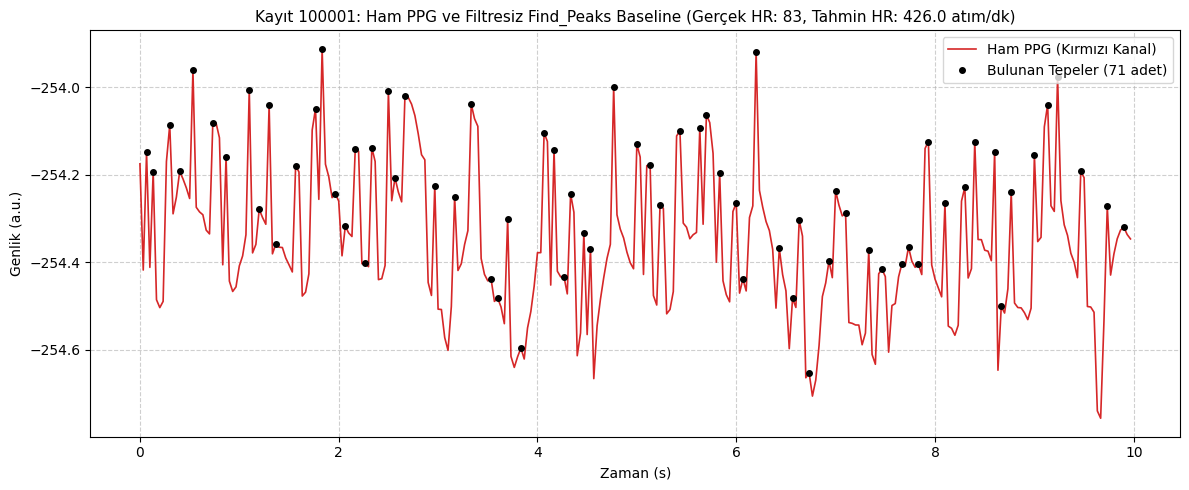

Şekil 1 başarıyla oluşturuldu ve 'sekil1.png' olarak kaydedildi!


In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import wfdb
from scipy.signal import find_peaks

# 1. Referans tablosunu okuyalım (ann değişkeni burada tanımlanıyor)
url_ann = "https://physionet.org/files/butppg/2.0.0/quality-hr-ann.csv"
ann = pd.read_csv(url_ann)

# 2. İlk kaydı ve verisini alalım
kayit_id = ann['ID'].iloc[0]
gercek_hr = ann['HR'].iloc[0]

record = wfdb.rdrecord(f"{kayit_id}_PPG", pn_dir=f"butppg/2.0.0/{kayit_id}")
fs = record.fs
raw_sig = record.p_signal

if raw_sig.shape[0] == 1:
    ppg = raw_sig.flatten()
elif raw_sig.ndim == 2 and raw_sig.shape[1] >= 3:
    ppg = raw_sig[:, 0]
elif raw_sig.ndim == 2 and raw_sig.shape[0] >= 3 and raw_sig.shape[1] > raw_sig.shape[0]:
    ppg = raw_sig[0, :]
else:
    ppg = raw_sig.flatten()

zaman = np.arange(len(ppg)) / fs

# Filtresiz Tepe Tespiti (Baseline)
tepeler, _ = find_peaks(ppg)
tepe_sayisi = len(tepeler)
sure = len(ppg) / fs
tahmin_hr = tepe_sayisi * (60.0 / sure)

# Şekil 1: Ham PPG ve Filtresiz Tepeler
plt.figure(figsize=(12, 5))
plt.plot(zaman, ppg, label='Ham PPG (Kırmızı Kanal)', color='tab:red', linewidth=1.2)
plt.plot(zaman[tepeler], ppg[tepeler], 'ko', markersize=4, label=f'Bulunan Tepeler ({tepe_sayisi} adet)')
plt.title(f'Kayıt {kayit_id}: Ham PPG ve Filtresiz Find_Peaks Baseline (Gerçek HR: {gercek_hr}, Tahmin HR: {tahmin_hr:.1f} atım/dk)', fontsize=11)
plt.xlabel('Zaman (s)', fontsize=10)
plt.ylabel('Genlik (a.u.)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig('sekil1.png', dpi=150)
plt.show()

print("Şekil 1 başarıyla oluşturuldu ve 'sekil1.png' olarak kaydedildi!")

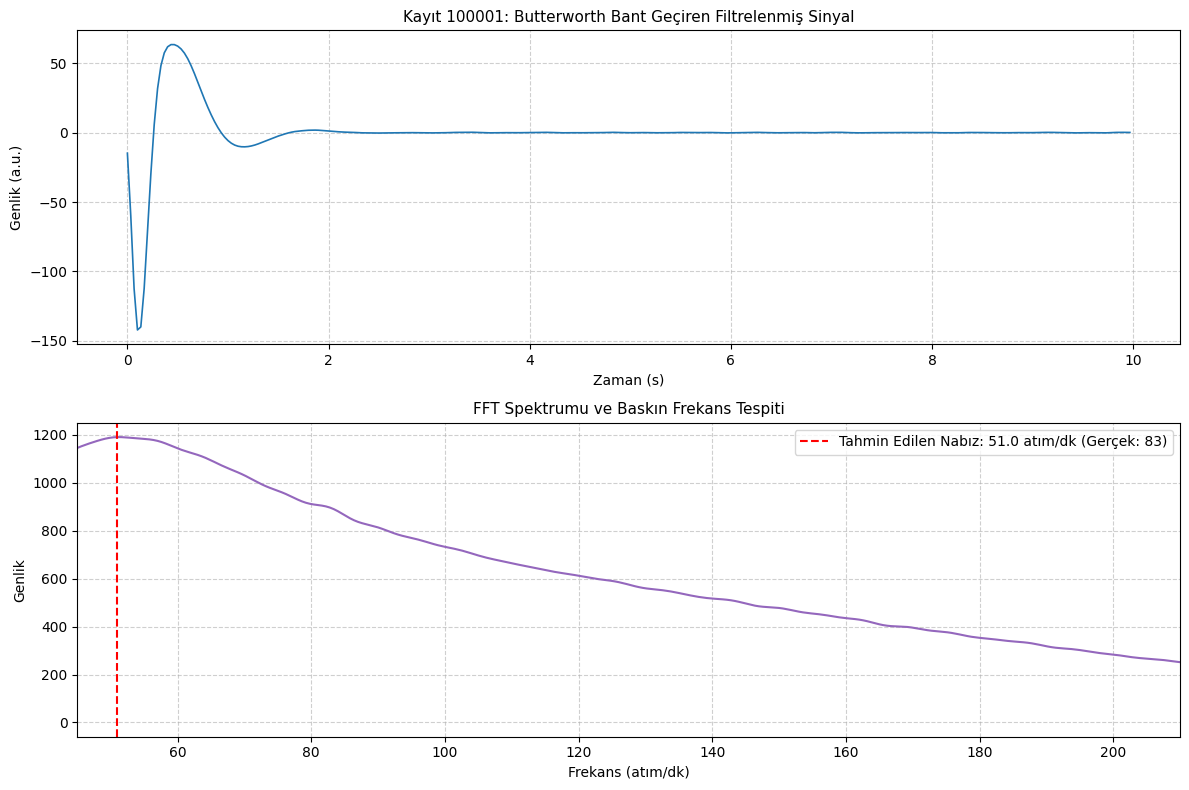

Şekil 2 başarıyla oluşturuldu ve 'sekil2.png' olarak kaydedildi!


In [55]:
from scipy.signal import butter, lfilter

def butter_bandpass(lowcut, highcut, fs, order=2):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return b, a

def butter_bandpass_filter(data, lowcut, highcut, fs, order=2):
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    y = lfilter(b, a, data)
    return y

# Filtre Parametreleri
f_alt = 0.75 # 45 atım/dk
f_ust = 3.5  # 210 atım/dk

# Sinyali filtrele
ppg_filt = butter_bandpass_filter(ppg, f_alt, f_ust, fs, order=2)
ppg_filt = ppg_filt - np.mean(ppg_filt) # DC bileşeni kaldır

# FFT Uygula (Zero-padding ile)
n_fft = 3000
fft_genlik = np.abs(np.fft.rfft(ppg_filt, n_fft))
frekanslar = np.fft.rfftfreq(n_fft, d=1/fs)

# Nabız aralığındaki en baskın frekansı bul
bant = (frekanslar >= f_alt) & (frekanslar <= f_ust)
baskintepe_frekans = frekanslar[bant][np.argmax(fft_genlik[bant])]
tahmin_fft_hr = baskintepe_frekans * 60.0

# Şekil 2: Filtrelenmiş Sinyal ve FFT Spektrumu
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

# Üst grafik: Filtrelenmiş Sinyal
ax1.plot(zaman, ppg_filt, color='tab:blue', linewidth=1.2)
ax1.set_title(f'Kayıt {kayit_id}: Butterworth Bant Geçiren Filtrelenmiş Sinyal', fontsize=11)
ax1.set_xlabel('Zaman (s)', fontsize=10)
ax1.set_ylabel('Genlik (a.u.)', fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.6)

# Alt grafik: FFT Spektrumu
ax2.plot(frekanslar * 60, fft_genlik, color='tab:purple', linewidth=1.5)
ax2.axvline(x=tahmin_fft_hr, color='r', linestyle='--', label=f'Tahmin Edilen Nabız: {tahmin_fft_hr:.1f} atım/dk (Gerçek: {gercek_hr})')
ax2.set_xlim(45, 210) # Nabız aralığı (atım/dk cinsinden)
ax2.set_title(f'FFT Spektrumu ve Baskın Frekans Tespiti', fontsize=11)
ax2.set_xlabel('Frekans (atım/dk)', fontsize=10)
ax2.set_ylabel('Genlik', fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.savefig('sekil2.png', dpi=150)
plt.show()

print("Şekil 2 başarıyla oluşturuldu ve 'sekil2.png' olarak kaydedildi!")

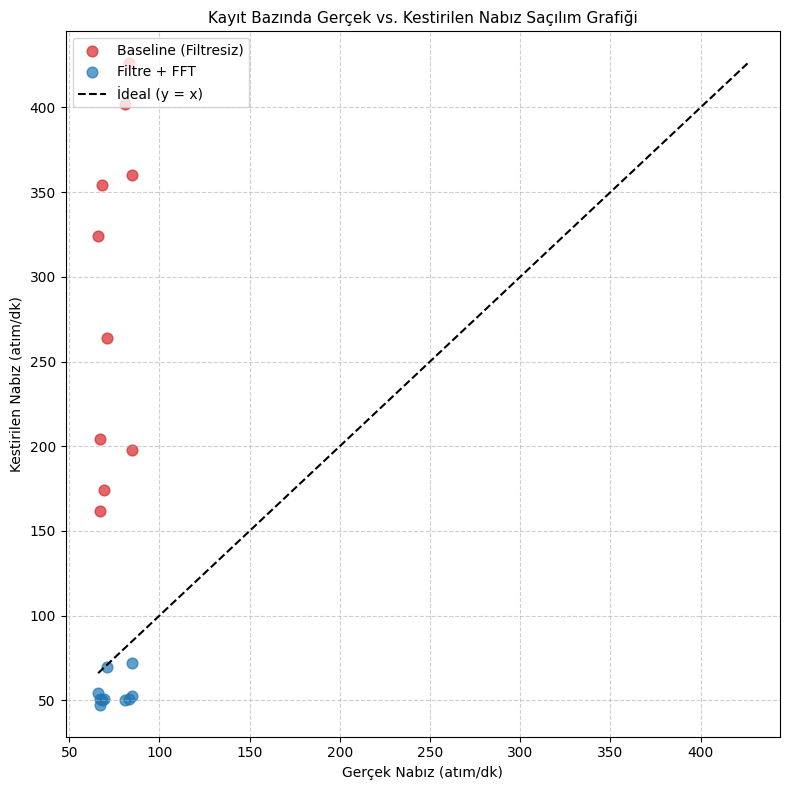

Şekil 3 başarıyla oluşturuldu ve 'sekil3.png' olarak kaydedildi!


In [56]:
# Şekil 3: Referans Nabza Karşı Kestirilen Nabız Saçılım Grafiği (İlk 10 Kayıt)
gercek_list = []
baseline_list = []
fft_list = []

for i in range(10):
    kid = ann['ID'].iloc[i]
    ghr = ann['HR'].iloc[i]

    # Veriyi yükle
    rec = wfdb.rdrecord(f"{kid}_PPG", pn_dir=f"butppg/2.0.0/{kid}")
    fs_val = rec.fs
    sig = rec.p_signal
    if sig.shape[0] == 1:
        p = sig.flatten()
    elif sig.ndim == 2 and sig.shape[1] >= 3:
        p = sig[:, 0]
    elif sig.ndim == 2 and sig.shape[0] >= 3 and sig.shape[1] > sig.shape[0]:
        p = sig[0, :]
    else:
        p = sig.flatten()

    # Baseline tahmin (Filtresiz)
    tp, _ = find_peaks(p)
    sure_val = len(p) / fs_val
    b_hr = len(tp) * (60.0 / sure_val)

    # Filtre + FFT tahmin
    p_f = butter_bandpass_filter(p, 0.75, 3.5, fs_val, order=2)
    p_f = p_f - np.mean(p_f)
    n_f = 3000
    fft_g = np.abs(np.fft.rfft(p_f, n_f))
    freqs = np.fft.rfftfreq(n_f, d=1/fs_val)
    b_mask = (freqs >= 0.75) & (freqs <= 3.5)
    f_hr = freqs[b_mask][np.argmax(fft_g[b_mask])] * 60.0

    gercek_list.append(ghr)
    baseline_list.append(b_hr)
    fft_list.append(f_hr)

plt.figure(figsize=(8, 8))
plt.scatter(gercek_list, baseline_list, color='tab:red', label='Baseline (Filtresiz)', alpha=0.7, s=60)
plt.scatter(gercek_list, fft_list, color='tab:blue', label='Filtre + FFT', alpha=0.7, s=60)

# y = x referans çizgisi
min_val = min(min(gercek_list), min(baseline_list))
max_val = max(max(gercek_list), max(baseline_list), max(fft_list))
plt.plot([min_val, max_val], [min_val, max_val], 'k--', label='İdeal (y = x)')

plt.title('Kayıt Bazında Gerçek vs. Kestirilen Nabız Saçılım Grafiği', fontsize=11)
plt.xlabel('Gerçek Nabız (atım/dk)', fontsize=10)
plt.ylabel('Kestirilen Nabız (atım/dk)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper left')
plt.tight_layout()
plt.savefig('sekil3.png', dpi=150)
plt.show()

print("Şekil 3 başarıyla oluşturuldu ve 'sekil3.png' olarak kaydedildi!")

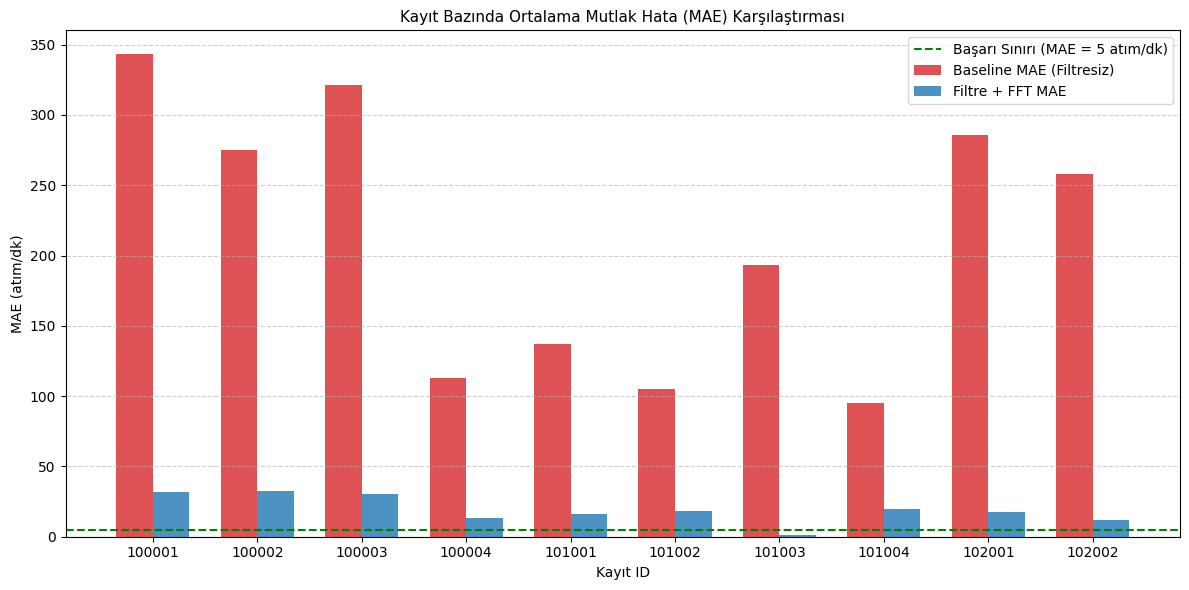

Şekil 4 başarıyla oluşturuldu ve 'sekil4.png' olarak kaydedildi!


In [46]:
# Şekil 4: Kayıt Bazında MAE Çubuk Grafiği
mae_baseline_list = []
mae_fft_list = []
kayit_ids = []

for i in range(10):
    kid = ann['ID'].iloc[i]
    ghr = ann['HR'].iloc[i]
    kayit_ids.append(str(kid))

    # Baseline hata (Mutlak hata)
    b_err = abs(baseline_list[i] - ghr)
    mae_baseline_list.append(b_err)

    # FFT hata (Mutlak hata)
    f_err = abs(fft_list[i] - ghr)
    mae_fft_list.append(f_err)

x = np.arange(len(kayit_ids))
width = 0.35

plt.figure(figsize=(12, 6))
plt.bar(x - width/2, mae_baseline_list, width, label='Baseline MAE (Filtresiz)', color='tab:red', alpha=0.8)
plt.bar(x + width/2, mae_fft_list, width, label='Filtre + FFT MAE', color='tab:blue', alpha=0.8)

plt.axhline(y=5, color='green', linestyle='--', label='Başarı Sınırı (MAE = 5 atım/dk)')

plt.title('Kayıt Bazında Ortalama Mutlak Hata (MAE) Karşılaştırması', fontsize=11)
plt.xlabel('Kayıt ID', fontsize=10)
plt.ylabel('MAE (atım/dk)', fontsize=10)
plt.xticks(x, kayit_ids)
plt.grid(True, linestyle='--', alpha=0.6, axis='y')
plt.legend(loc='upper right')
plt.tight_layout()
plt.savefig('sekil4.png', dpi=150)
plt.show()

print("Şekil 4 başarıyla oluşturuldu ve 'sekil4.png' olarak kaydedildi!")